# Phase I · 01 · Training-data exploration

**Phase I asks how a model behaves, treating it as a black box.** This notebook comes first because it does not use a model at all. It looks at the **88,702 cleaned training images** for visible differences between REAL and FAKE images, the kind of difference a detector could learn as a shortcut. These differences become the hypotheses that the behaviour notebooks test.

| Phase I notebook | Question |
| --- | --- |
| `01_training_data_exploration.ipynb` | What differs between REAL and FAKE training images before any model sees them? |
| `02_cnn_behaviour.ipynb` | How do the baseline CNN's outputs move when we edit the images? |
| `03_resnet18_behaviour.ipynb` | The same edits for the fine-tuned ResNet18 |
| `04_what_fools_the_detectors.ipynb` | Which systematic patterns sit behind the errors of both models? |

The cells and figures are Section 4 of `baseline_training.ipynb`, moved here unchanged. That notebook still prepares and audits the data split; this one only reads the result. Without the local training cache, the figures bundled inside this notebook are shown and no download is needed. The clickable thumbnail explorer needs the prepared training data and a live kernel.

## 1. Environment and notebook implementation

Use Python 3.12 and select that environment as the notebook kernel in VS Code or Jupyter. If dependencies are missing, set `INSTALL_DEPENDENCIES = True` in the next cell, run it once, restart the kernel if prompted, then set it back to `False`. This installs packages in the current kernel environment; the default Run All does not install or download anything.

The helper cells below contain the entire implementation. The collapsed **bundled baseline** cell carries the selected trained weights, numerical results, and static figures, so copying this `.ipynb` is enough to share the baseline. You can leave that cell collapsed.

In [1]:
INSTALL_DEPENDENCIES = False
PACKAGES = [
    "kagglehub==1.0.3",
    "torch==2.15.0",
    "numpy==2.5.4",
    "pillow==13.0.0",
    "scikit-learn==1.9.1",
    "matplotlib==3.11.2",
    "jupyterlab==4.6.5",
    "ipykernel==7.4.0",
    "nbformat==5.11.1",
    "nbclient==0.11.0",
    "plotly==7.1.0",
    "anywidget==0.11.0",
    "ipywidgets==8.1.9",
]

if INSTALL_DEPENDENCIES:
    get_ipython().run_line_magic("pip", "install " + " ".join(PACKAGES))
else:
    print("Using the current kernel environment; installation is disabled.")


Using the current kernel environment; installation is disabled.


In [2]:
from pathlib import Path
from collections import Counter, defaultdict
from datetime import datetime, timezone
from io import BytesIO, StringIO
from types import SimpleNamespace
import base64
import csv
import hashlib
import importlib.metadata
import json
import logging
import os
import platform
import random
import shutil
import sys
import tarfile
import tempfile
import time

NOTEBOOK_PATH = Path.cwd().resolve() / "01_training_data_exploration.ipynb"
# Phase notebooks sit one folder below the repository root; data, runs and results stay at the root.
ROOT = next(
    (p for p in (NOTEBOOK_PATH.parent, *NOTEBOOK_PATH.parents) if (p / "team-info.json").exists()),
    NOTEBOOK_PATH.parent,
)
os.environ.setdefault(
    "MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "cifake-matplotlib")
)

import numpy as np
import torch
from torch import nn
from PIL import Image
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, roc_auc_score
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

get_ipython().run_line_magic("matplotlib", "inline")
torch.set_num_threads(4)


def read_json(path):
    return json.loads(Path(path).read_text())


def read_csv(path):
    with Path(path).open(newline="") as handle:
        return list(csv.DictReader(handle))


def show_table(headers, rows):
    lines = [
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join(["---"] * len(headers)) + " |",
    ]
    lines += ["| " + " | ".join(str(value) for value in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))


def snapshot_notebook(source_dir):
    """Record the notebook and the code actually executed for a new training run."""
    if not NOTEBOOK_PATH.is_file():
        raise FileNotFoundError(
            "Save this notebook and set NOTEBOOK_PATH to its filename before training."
        )
    shutil.copy2(NOTEBOOK_PATH, source_dir / "baseline_training.ipynb")
    shell = get_ipython()
    if shell is not None:
        inputs = [
            s
            for s in shell.history_manager.input_hist_raw
            if s and "EMBEDDED_ASSETS =" not in s
        ]
        (source_dir / "executed_cells.txt").write_text(
            "\n\n# --- next executed cell ---\n\n".join(inputs)
        )


print(f"Python {sys.version.split()[0]} · PyTorch {torch.__version__}")
print("Working directory:", ROOT)


### Bundled baseline and reusable notebook functions

Run the following cells once. They define the helpers without starting training; the bundled baseline cell can stay collapsed.

**Saved review data.** The trained weights and saved measurements are stored in notebook metadata, so there is no long encoded string to scroll through. This short loader checks and decodes the data when needed. Keep the complete `.ipynb` file when sharing it.

In [3]:
# These assets travel inside the .ipynb, outside the visible code cells.
# They include the trained CNN, saved metrics and the figures used in review mode.
_NOTEBOOK_PAYLOADS = None


def notebook_payload(name):
    """Read the saved notebook once and retrieve one embedded data block."""
    global _NOTEBOOK_PAYLOADS
    if _NOTEBOOK_PAYLOADS is None:
        if not NOTEBOOK_PATH.is_file():
            raise FileNotFoundError(
                "Save this notebook and set NOTEBOOK_PATH to its filename before review."
            )
        saved_notebook = json.loads(NOTEBOOK_PATH.read_text(encoding="utf-8"))
        _NOTEBOOK_PAYLOADS = saved_notebook["metadata"]["cifake"]
    return _NOTEBOOK_PAYLOADS[name]


# Bundled selected model and saved results. Leave this cell collapsed.
EMBEDDED_RUN = "baseline_plain_seed1"
EMBEDDED_ASSETS = notebook_payload("baseline_assets")


def embedded_bytes(name):
    """Decode one bundled asset and check its checksum before using it."""
    item = EMBEDDED_ASSETS.get(name)
    if item is None:
        return None
    raw = base64.b64decode(item["base64"], validate=True)
    if hashlib.sha256(raw).hexdigest() != item["sha256"]:
        raise ValueError(f"Bundled artifact integrity check failed: {name}")
    return raw


for artifact_name in EMBEDDED_ASSETS:
    embedded_bytes(artifact_name)
print(
    "Bundled baseline verified: trained weights, metrics, history, and static figures are available in memory."
)


Bundled baseline verified: trained weights, metrics, history, and static figures are available in memory.


**The baseline architecture.** The model is a small CNN with two convolution-and-pooling stages and a 64-unit hidden layer. Its output is a REAL logit; converting it to a probability and applying the fixed threshold happens in the evaluation helpers.

In [4]:
LABELS = {"FAKE": 0, "REAL": 1}  # Matches the paper; sigmoid(logit) = P(REAL).


class BaselineCNN(nn.Module):
    """Paper-inspired 32/32 convolutional filters and one 64-unit dense layer.

    3x3 valid convolutions, ReLU, 2x2 max pooling after each convolution.
    32x32 -> 30x30 -> 15x15 -> 13x13 -> 6x6 -> 1152 -> 64 -> 1.
    No augmentation, dropout, batch normalization, or pretrained weights.
    """

    def __init__(self):
        super().__init__()
        # Learn local patterns, then reduce their spatial size with max pooling.
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 32, 3),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        # Combine the 32 feature maps into 64 hidden values and one REAL logit.
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(1152, 64), nn.ReLU(), nn.Linear(64, 1)
        )
        # Initialize this small network from scratch; no pretrained weights are used.
        for layer in self.modules():
            if isinstance(layer, (nn.Conv2d, nn.Linear)):
                nn.init.xavier_uniform_(layer.weight)
                nn.init.zeros_(layer.bias)

    def forward(self, x):
        return self.classifier(self.features(x)).squeeze(1)


**Data integrity and predictions.** These helpers check the data, prepare batches and calculate metrics. File checksums keep the split consistent when the notebook is shared.

In [5]:
def file_sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


def write_json(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False) + "\n")
    temporary.replace(path)


def choose_device(name="auto"):
    if name == "auto":
        name = (
            "cuda"
            if torch.cuda.is_available()
            else "mps" if torch.backends.mps.is_available() else "cpu"
        )
    if name == "mps" and not torch.backends.mps.is_available():
        raise RuntimeError(
            "MPS is unavailable in this process. Use an allowed GPU process or --device cpu."
        )
    return torch.device(name)


def verify_run_data(data_dir, run_dir, config):
    """Compare content, not machine-specific absolute paths, for team portability."""
    data_dir, run_dir = Path(data_dir), Path(run_dir)
    expected = json.loads((run_dir / "data_audit.json").read_text())
    actual = json.loads((data_dir / "audit.json").read_text())
    if (
        file_sha256(data_dir / "manifest.csv") != config["manifest_sha256"]
        or actual["file_sha256"] != expected["file_sha256"]
    ):
        raise ValueError("Prepared dataset differs from the data used in this run")


def load_split(data_dir, split):
    """Verify cached data against the audit before using it."""
    data_dir = Path(data_dir)
    audit = json.loads((data_dir / "audit.json").read_text())
    for filename in ("manifest.csv", f"{split}_images.npy", f"{split}_labels.npy"):
        if file_sha256(data_dir / filename) != audit["file_sha256"][filename]:
            raise ValueError(f"Prepared file changed after audit: {filename}")
    images = np.load(data_dir / f"{split}_images.npy", allow_pickle=False)
    labels = np.load(data_dir / f"{split}_labels.npy", allow_pickle=False)
    with (data_dir / "manifest.csv").open(newline="") as handle:
        rows = [row for row in csv.DictReader(handle) if row["split"] == split]
    if images.dtype != np.uint8 or images.shape != (len(rows), 3, 32, 32):
        raise ValueError(f"Invalid image cache for {split}")
    if not np.array_equal(labels, [int(row["label"]) for row in rows]):
        raise ValueError(f"Labels do not match manifest for {split}")
    return images, labels, rows


def batches(images, labels, batch_size, device, order=None):
    if order is None:
        order = np.arange(len(labels))
    for offset in range(0, len(order), batch_size):
        idx = order[offset : offset + batch_size]
        x = (
            torch.from_numpy(images[idx])
            .to(device=device, dtype=torch.float32)
            .div_(255)
        )
        y = torch.from_numpy(labels[idx]).to(device=device, dtype=torch.float32)
        yield x, y


@torch.inference_mode()
def predict(model, images, labels, batch_size, device):
    """Run evaluation batches without updating the weights or tracking gradients."""
    model.eval()
    logits = [
        model(x).cpu().numpy() for x, _ in batches(images, labels, batch_size, device)
    ]
    return np.concatenate(logits)


def classification_metrics(labels, logits):
    """Summarize predictions with FAKE=0, REAL=1 and a fixed 0.5 threshold."""
    logits = np.asarray(logits, dtype=np.float64)
    labels = np.asarray(labels, dtype=np.int64)
    if len(labels) != len(logits) or not np.isfinite(logits).all():
        raise ValueError("Invalid predictions")
    predicted = (logits >= 0).astype(np.int64)
    cm = confusion_matrix(labels, predicted, labels=[0, 1])
    # Stable BCE and sigmoid. Threshold is fixed in advance at P(REAL) >= 0.5.
    p_real = np.exp(-np.logaddexp(0, -logits))
    return {
        "n": len(labels),
        "loss": float(np.mean(np.logaddexp(0, logits) - labels * logits)),
        "accuracy": float(accuracy_score(labels, predicted)),
        "balanced_accuracy": float(np.mean(np.diag(cm) / cm.sum(axis=1))),
        "f1_fake": float(f1_score(labels, predicted, pos_label=0)),
        "roc_auc_fake": float(roc_auc_score(labels == 0, -logits)),
        "fake_detection_rate": float(cm[0, 0] / cm[0].sum()),
        "real_flagged_fake_rate": float(cm[1, 0] / cm[1].sum()),
        "brier_score_fake": float(np.mean(((1 - p_real) - (labels == 0)) ** 2)),
        "confusion_matrix": cm.tolist(),
        "confusion_matrix_order": ["FAKE", "REAL"],
        "confusion_matrix_axes": "rows=true, columns=predicted",
        "decision_rule": "REAL if sigmoid(logit) >= 0.5, otherwise FAKE",
    }


def save_predictions(path, rows, logits):
    p_real = np.exp(-np.logaddexp(0, -np.asarray(logits, dtype=np.float64)))
    with Path(path).open("w", newline="") as handle:
        writer = csv.writer(handle)
        writer.writerow(
            [
                "path",
                "pixel_sha256",
                "label",
                "class_name",
                "logit_real",
                "p_real",
                "p_fake",
                "prediction",
                "correct",
            ]
        )
        for row, logit, probability in zip(rows, logits, p_real, strict=True):
            prediction = "REAL" if logit >= 0 else "FAKE"
            writer.writerow(
                [
                    row["path"],
                    row["pixel_sha256"],
                    row["label"],
                    row["class_name"],
                    float(logit),
                    float(probability),
                    float(1 - probability),
                    prediction,
                    prediction == row["class_name"],
                ]
            )


In [6]:
def assign_splits(records, validation_per_class=5000, seed=1):
    """Keep the official test set. Deduplicate development data before sampling."""
    labels_by_hash = defaultdict(set)
    for row in records:
        labels_by_hash[row["pixel_sha256"]].add(row["label"])
    if any(len(labels) != 1 for labels in labels_by_hash.values()):
        raise ValueError(
            "Identical pixels have conflicting labels; resolve before training."
        )
    test_hashes = {r["pixel_sha256"] for r in records if r["source_split"] == "test"}
    seen = set()
    for row in records:
        row["exclusion_reason"] = ""
        if row["source_split"] == "test":
            row["split"] = "test"
        elif row["pixel_sha256"] in test_hashes:
            row["split"], row["exclusion_reason"] = (
                "excluded",
                "identical_to_official_test",
            )
        elif row["pixel_sha256"] in seen:
            row["split"], row["exclusion_reason"] = (
                "excluded",
                "repeated_training_image",
            )
        else:
            row["split"] = "train"
            seen.add(row["pixel_sha256"])
    rng = np.random.default_rng(seed)
    for label in LABELS.values():
        eligible = [
            i
            for i, r in enumerate(records)
            if r["split"] == "train" and r["label"] == label
        ]
        if len(eligible) <= validation_per_class:
            raise ValueError(
                "Not enough unique images for the requested validation size"
            )
        for idx in rng.permutation(eligible)[:validation_per_class]:
            records[idx]["split"] = "val"
    hashes = {
        s: {r["pixel_sha256"] for r in records if r["split"] == s}
        for s in ("train", "val", "test")
    }
    if (
        hashes["train"] & hashes["val"]
        or hashes["train"] & hashes["test"]
        or hashes["val"] & hashes["test"]
    ):
        raise AssertionError("Pixel overlap across splits")
    return records


def prepare_data(data_root, output, seed=1, validation_per_class=5000):
    """Audit the images, assign the fixed splits and save arrays for training."""
    args = SimpleNamespace(
        data_root=Path(data_root),
        output=Path(output),
        seed=seed,
        validation_per_class=validation_per_class,
    )
    if args.output.exists():
        raise SystemExit(
            f"Refusing to overwrite {args.output}; reuse it or choose a new --output."
        )
    if args.validation_per_class < 1:
        raise SystemExit("Validation size must be positive")

    records, images = [], []
    for source in ("train", "test"):
        for class_name, label in LABELS.items():
            paths = sorted((args.data_root / source / class_name).glob("*.jpg"))
            expected = 50000 if source == "train" else 10000
            if len(paths) != expected:
                raise ValueError(
                    f"{source}/{class_name}: expected {expected}, found {len(paths)}"
                )
            for path in paths:
                with Image.open(path) as im:
                    if im.size != (32, 32) or im.mode != "RGB":
                        raise ValueError(f"Expected 32x32 RGB: {path}")
                    pixels = np.array(im, dtype=np.uint8)
                images.append(pixels.transpose(2, 0, 1))
                records.append(
                    {
                        "path": path.relative_to(args.data_root).as_posix(),
                        "source_split": source,
                        "class_name": class_name,
                        "label": label,
                        "pixel_sha256": hashlib.sha256(pixels.tobytes()).hexdigest(),
                    }
                )
            print(
                f"Decoded and hashed {source}/{class_name}: {len(paths):,}", flush=True
            )
    assign_splits(records, args.validation_per_class, args.seed)
    args.output.mkdir(parents=True)
    fields = [
        "path",
        "source_split",
        "class_name",
        "label",
        "pixel_sha256",
        "split",
        "exclusion_reason",
    ]
    with (args.output / "manifest.csv").open("w", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=fields)
        writer.writeheader()
        writer.writerows(records)
    for split in ("train", "val", "test"):
        indices = [i for i, r in enumerate(records) if r["split"] == split]
        np.save(
            args.output / f"{split}_images.npy", np.stack([images[i] for i in indices])
        )
        np.save(
            args.output / f"{split}_labels.npy",
            np.array([records[i]["label"] for i in indices], dtype=np.int64),
        )
    counts = {
        s: dict(Counter(r["class_name"] for r in records if r["split"] == s))
        for s in ("train", "val", "test", "excluded")
    }
    test_hashes = [r["pixel_sha256"] for r in records if r["split"] == "test"]
    all_hashes = Counter(r["pixel_sha256"] for r in records)
    audit = {
        "seed": args.seed,
        "validation_per_class": args.validation_per_class,
        "source_root": str(args.data_root.resolve()),
        "class_to_index": LABELS,
        "split_counts": counts,
        "exclusion_counts": dict(
            Counter(r["exclusion_reason"] for r in records if r["split"] == "excluded")
        ),
        "duplicate_groups_in_original_data": sum(v > 1 for v in all_hashes.values()),
        "official_test_size": len(test_hashes),
        "unique_test_images": len(set(test_hashes)),
        "exact_pixel_overlap_across_splits": 0,
        "policy": "Preserve official test; exclude training copies of test images; retain one copy of each remaining training image; seeded balanced validation holdout.",
        "limitations": "Exact decoded RGB duplicates only; near-duplicates are not detected. Stratified by REAL/FAKE, not unverified semantic classes.",
        "preprocessing": "Decode RGB at native 32x32; float32 / 255 at batch time; no augmentation.",
        "file_sha256": {
            p.name: file_sha256(p) for p in sorted(args.output.iterdir()) if p.is_file()
        },
    }
    write_json(args.output / "audit.json", audit)
    print(f"Split counts: {counts}", flush=True)
    print(
        f"Exclusions: {audit['exclusion_counts']}; unique test images: {len(set(test_hashes)):,}",
        flush=True,
    )
    print(f"Prepared data: {args.output}", flush=True)


## 2. Configuration

This notebook only **reviews** the saved baseline. Training, resuming and the official test evaluation live in `baseline_training.ipynb`. `SPLIT_SEED` and `RUN_NAME` must match the run whose weights are bundled here.

In [7]:
# Keep review mode to inspect the saved experiment. Use a new run name for a new training experiment.
MODE = "review"  # Fixed: train in baseline_training.ipynb.
RUN_NAME = "baseline_plain_seed1"  # Use a NEW name to train another model.
DEVICE = "auto"  # "auto", "mps", "cuda", or "cpu"

SAVE_FIGURES = False  # Optional local PNG/summary copies.
DOWNLOAD_DATA = False
PREPARE_DATA = False

SPLIT_SEED = 1
VALIDATION_PER_CLASS = 5000
TRAINING = {
    "seed": 1,
    "epochs": 30,
    "batch_size": 128,
    "learning_rate": 0.001,
    "patience": 5,
    "min_delta": 0.0001,
}

assert MODE in {"review", "train", "resume"}
assert RUN_NAME and Path(RUN_NAME).name == RUN_NAME and RUN_NAME not in {".", ".."}
RAW_DATA = ROOT / "data" / "cifake"
DATA_DIR = ROOT / "data" / f"baseline_seed{SPLIT_SEED}"
RUN_DIR = ROOT / "runs" / RUN_NAME
RESULTS_DIR = ROOT / "results" / RUN_NAME
MODEL_PATH = ROOT / "models" / f"{RUN_NAME}.pt"
device = choose_device(DEVICE)


def result_bytes(name):
    for directory in (RUN_DIR, RESULTS_DIR):
        path = directory / name
        if path.exists():
            return path.read_bytes()
    if RUN_NAME == EMBEDDED_RUN and SPLIT_SEED == 1:
        return embedded_bytes(f"results/{EMBEDDED_RUN}/{name}")
    return None


def read_result(name):
    raw = result_bytes(name)
    if raw is None:
        return None
    if name.endswith(".csv"):
        return list(csv.DictReader(StringIO(raw.decode("utf-8"))))
    return json.loads(raw)


show_table(
    ["Setting", "Value"],
    [
        ("Mode", MODE),
        ("Run", RUN_NAME),
        ("Device", str(device)),
        ("Augmentation", "None"),
        *TRAINING.items(),
    ],
)

| Setting | Value |
| --- | --- |
| Mode | review |
| Run | baseline_plain_seed1 |
| Device | mps |
| Augmentation | None |
| seed | 1 |
| epochs | 30 |
| batch_size | 128 |
| learning_rate | 0.001 |
| patience | 5 |
| min_delta | 0.0001 |

## 3. Data and a split without exact duplicate leakage

CIFAKE's official split has 100,000 development images and 20,000 test images. We preserve all official test images, exclude development images with identical test pixels, keep one copy of each remaining development image, and reserve 5,000 images of each label for validation.

| Split | FAKE | REAL | Total |
| --- | ---: | ---: | ---: |
| Training | 43,702 | 45,000 | 88,702 |
| Validation | 5,000 | 5,000 | 10,000 |
| Official test | 10,000 | 10,000 | 20,000 |

The audit excluded **378 test overlaps** and **920 repeated training copies**, all FAKE. Hashes are calculated from decoded RGB pixels, not filenames. The test set contains 38 repeated copies, so we also report metrics on its 19,962 unique images. Near-duplicates have not been screened. Stratification uses REAL/FAKE; semantic classes are not inferred from filenames.

The next cell only downloads or prepares data when the corresponding configuration flag is enabled. Existing prepared data is reused.

In [8]:
if DOWNLOAD_DATA:
    os.environ.setdefault("KAGGLEHUB_CACHE", str(ROOT / "data" / ".kagglehub"))
    import kagglehub

    kagglehub.dataset_download(
        "birdy654/cifake-real-and-ai-generated-synthetic-images",
        output_dir=str(RAW_DATA),
    )

if PREPARE_DATA and not (DATA_DIR / "audit.json").exists():
    prepare_data(
        RAW_DATA, DATA_DIR, seed=SPLIT_SEED, validation_per_class=VALIDATION_PER_CLASS
    )

if (DATA_DIR / "audit.json").exists():
    audit = read_json(DATA_DIR / "audit.json")
    if (
        audit["seed"] != SPLIT_SEED
        or audit["validation_per_class"] != VALIDATION_PER_CLASS
    ):
        raise ValueError(
            "Prepared split settings differ. Reuse its settings or choose a new DATA_DIR."
        )
    print("Using the existing prepared split.")
else:
    audit = read_result("data_audit.json")
    print(
        "Prepared pixel cache is absent. Review uses the bundled audit; enable PREPARE_DATA to train."
    )

if audit:
    show_table(
        ["Split", "FAKE", "REAL", "Total"],
        [
            [split, counts.get("FAKE", 0), counts.get("REAL", 0), sum(counts.values())]
            for split, counts in audit["split_counts"].items()
        ],
    )
    print("Exclusions:", audit["exclusion_counts"])
    print(
        "Exact pixel overlap across splits:", audit["exact_pixel_overlap_across_splits"]
    )


Prepared pixel cache is absent. Review uses the bundled audit; enable PREPARE_DATA to train.


| Split | FAKE | REAL | Total |
| --- | --- | --- | --- |
| train | 43702 | 45000 | 88702 |
| val | 5000 | 5000 | 10000 |
| test | 10000 | 10000 | 20000 |
| excluded | 1298 | 0 | 1298 |

Exclusions: {'identical_to_official_test': 378, 'repeated_training_image': 920}
Exact pixel overlap across splits: 0


In [9]:
# Recheck split membership when the local manifest is available. This reads metadata, not model outputs.
manifest_path = DATA_DIR / "manifest.csv"
if manifest_path.exists():
    assert file_sha256(manifest_path) == audit["file_sha256"]["manifest.csv"]
    manifest = read_csv(manifest_path)
    split_hashes = {
        split: {row["pixel_sha256"] for row in manifest if row["split"] == split}
        for split in ("train", "val", "test")
    }
    assert not (split_hashes["train"] & split_hashes["val"])
    assert not (split_hashes["train"] & split_hashes["test"])
    assert not (split_hashes["val"] & split_hashes["test"])
    assert len(split_hashes["train"]) == sum(audit["split_counts"]["train"].values())
    assert len(split_hashes["val"]) == 2 * VALIDATION_PER_CLASS
    print(
        "Verified: no exact duplicate leakage, and unique training/validation images."
    )
    del manifest, split_hashes
else:
    print(
        "Live membership check skipped: the saved audit is available, but this clone has no local manifest."
    )


Live membership check skipped: the saved audit is available, but this clone has no local manifest.


## 4. Data exploration · What differs before model inference?

These visualizations were added after the first baseline run, but their calculations do not use the trained model or its predictions. Image-property statistics and spectra use **all 88,702 cleaned training images**. Random galleries and the scatterplot use reproducible samples. The duplicate audit reads split metadata, and its example images come only from the original training pool.

**Questions:** Are real and fake images visibly different? Do simple brightness, contrast, saturation, or sharpness statistics differ? What data-quality issues could otherwise inflate evaluation? Are there differences in spatial-frequency content that motivate later blur/compression experiments?

Blue denotes **REAL**, orange denotes **FAKE** throughout this section. Images remain at 32×32 for calculations; enlargements are for display only. If local training data is absent, the figures bundled inside this notebook provide a static review. The clickable explorer needs a live Jupyter kernel and the local training cache.

In [10]:
from collections import defaultdict
from io import BytesIO
import html
from PIL import Image as PILImage
from IPython.display import Image as DisplayImage

EDA_SEED = 2026
EDA_DIR = ROOT / "results" / f"eda_baseline_seed{SPLIT_SEED}"
EDA_COLORS = {"REAL": "#0072B2", "FAKE": "#D55E00"}
EDA_CLASS_ORDER = [("REAL", 1), ("FAKE", 0)]
EDA_PROPERTIES = ["brightness", "contrast", "saturation", "sharpness"]
EDA_PROPERTY_LABELS = {
    "brightness": "Mean luma (0–1)",
    "contrast": "Luma standard deviation",
    "saturation": "Mean HSV saturation (0–1)",
    "sharpness": "Laplacian variance",
    "log_sharpness": "log₁₀(Laplacian variance + 10⁻⁸)",
}


def finish_eda_figure(fig, name):
    if SAVE_FIGURES:
        EDA_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(
            EDA_DIR / f"{name}.png", dpi=160, bbox_inches="tight", facecolor="white"
        )
    plt.show()
    plt.close(fig)


def show_saved_eda(name):
    saved = EDA_DIR / f"{name}.png"
    if saved.exists():
        display(DisplayImage(filename=str(saved)))
        print("Saved training-data visualization; no local image cache was read.")
    elif SPLIT_SEED == 1:
        raw = embedded_bytes(f"results/eda_baseline_seed1/{name}.png")
        if raw is not None:
            display(DisplayImage(data=raw))
            print("Bundled training-data visualization; no local dataset is required.")
        else:
            print("Prepare the training data to generate this visualization.")
    else:
        print(
            "Prepare the training data and rerun this section to generate this visualization."
        )


def style_eda_axes(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.14)
    ax.set_axisbelow(True)


eda_images, eda_labels, eda_rows = None, None, []
eda_manifest = []
if (DATA_DIR / "train_images.npy").exists():
    eda_images, eda_labels, eda_rows = load_split(DATA_DIR, "train")
    assert all(
        row["split"] == "train" and row["source_split"] == "train" for row in eda_rows
    )
    eda_manifest = read_csv(DATA_DIR / "manifest.csv")
    print(
        f"EDA loaded {len(eda_labels):,} training images. Validation/test image arrays were not loaded."
    )
    print(
        "Image tensor:",
        eda_images.shape,
        eda_images.dtype,
        "· values",
        int(eda_images.min()),
        "to",
        int(eda_images.max()),
    )
else:
    print("No local training cache. Saved plots will be shown where available.")


No local training cache. Saved plots will be shown where available.


### 4.1 Split balance and exact duplicates

We'll start by checking how many real and fake images we actually have to work with. The first panel will show the original development and test sets, and the second will show the training, validation, and test sets after cleaning and setting aside validation images. Putting the real and fake counts next to each other makes any class imbalance easy to spot. The third panel will show why development images were excluded: either their pixels also appeared in the test set, or they were repeated within the development pool. These bars count excluded copies; the original image files are still preserved. The official test set retains its 38 repeated copies, which we account for separately in the unique-image evaluation.

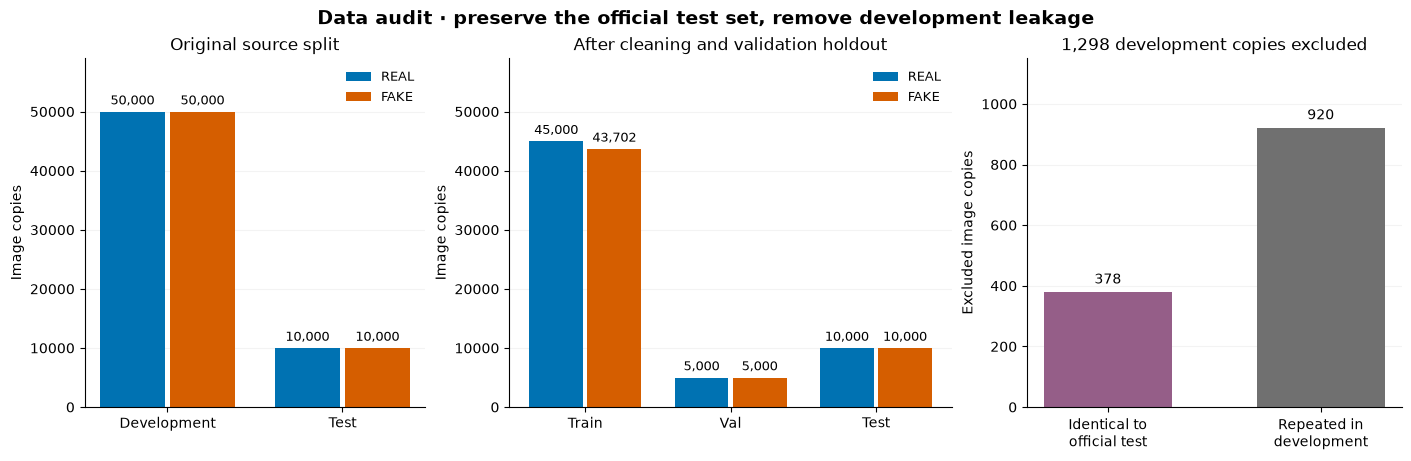

Original development/test overlap: 378 exact pixel hashes.
Final train/validation/test overlap: 0.
Official test contains 38 repeated copies.


In [11]:
if audit:
    if eda_manifest:
        original_counts = {
            source: {
                name: sum(
                    row["source_split"] == source and row["class_name"] == name
                    for row in eda_manifest
                )
                for name, _ in EDA_CLASS_ORDER
            }
            for source in ("train", "test")
        }
        before_hashes = {
            source: {
                r["pixel_sha256"] for r in eda_manifest if r["source_split"] == source
            }
            for source in ("train", "test")
        }
        overlap_before = len(before_hashes["train"] & before_hashes["test"])
        assert overlap_before == audit["exclusion_counts"]["identical_to_official_test"]
    else:
        original_counts = {
            "train": {
                name: sum(
                    audit["split_counts"][s].get(name, 0)
                    for s in ("train", "val", "excluded")
                )
                for name, _ in EDA_CLASS_ORDER
            },
            "test": audit["split_counts"]["test"],
        }
        overlap_before = audit["exclusion_counts"]["identical_to_official_test"]
    fig, axes = plt.subplots(
        1,
        3,
        figsize=(14, 4.5),
        layout="constrained",
        gridspec_kw={"width_ratios": [1, 1.3, 1.1]},
    )
    for ax, names, counts, title in [
        (axes[0], ["train", "test"], original_counts, "Original source split"),
        (
            axes[1],
            ["train", "val", "test"],
            audit["split_counts"],
            "After cleaning and validation holdout",
        ),
    ]:
        positions = np.arange(len(names))
        for offset, (name, _) in zip([-0.2, 0.2], EDA_CLASS_ORDER):
            bars = ax.bar(
                positions + offset,
                [counts[s].get(name, 0) for s in names],
                width=0.37,
                label=name,
                color=EDA_COLORS[name],
            )
            ax.bar_label(
                bars,
                labels=[f"{int(b.get_height()):,}" for b in bars],
                padding=3,
                fontsize=9,
            )
        ax.set(
            xticks=positions,
            xticklabels=[
                "Development" if s == "train" and ax is axes[0] else s.title()
                for s in names
            ],
            ylabel="Image copies",
            title=title,
            ylim=(0, 59000),
        )
        ax.legend(frameon=False, fontsize=9)
        style_eda_axes(ax)
    reasons = ["Identical to\nofficial test", "Repeated in\ndevelopment"]
    values = [
        audit["exclusion_counts"]["identical_to_official_test"],
        audit["exclusion_counts"]["repeated_training_image"],
    ]
    bars = axes[2].bar(reasons, values, color=["#955E88", "#707070"], width=0.6)
    axes[2].bar_label(bars, padding=4)
    axes[2].set(
        title=f"{sum(values):,} development copies excluded",
        ylabel="Excluded image copies",
        ylim=(0, max(values) * 1.25),
    )
    style_eda_axes(axes[2])
    fig.suptitle(
        "Data audit · preserve the official test set, remove development leakage",
        fontsize=14,
        fontweight="bold",
    )
    finish_eda_figure(fig, "01_split_audit")
    print(f"Original development/test overlap: {overlap_before:,} exact pixel hashes.")
    print(
        f"Final train/validation/test overlap: {audit['exact_pixel_overlap_across_splits']}."
    )
    print(
        f"Official test contains {audit['official_test_size'] - audit['unique_test_images']} repeated copies."
    )


To make those duplicate counts more concrete, we'll also look at three pairs of images from the original training pool. Each row will place a retained training image beside a repeated copy that was excluded, with the filenames shown above them. We choose these pairs from groups with exactly matching decoded pixels, then check the pixels again before displaying them. This shows why different filenames do not necessarily mean different examples. These are exact duplicates rather than merely similar-looking pictures, and neither side of the comparison comes from the test set.

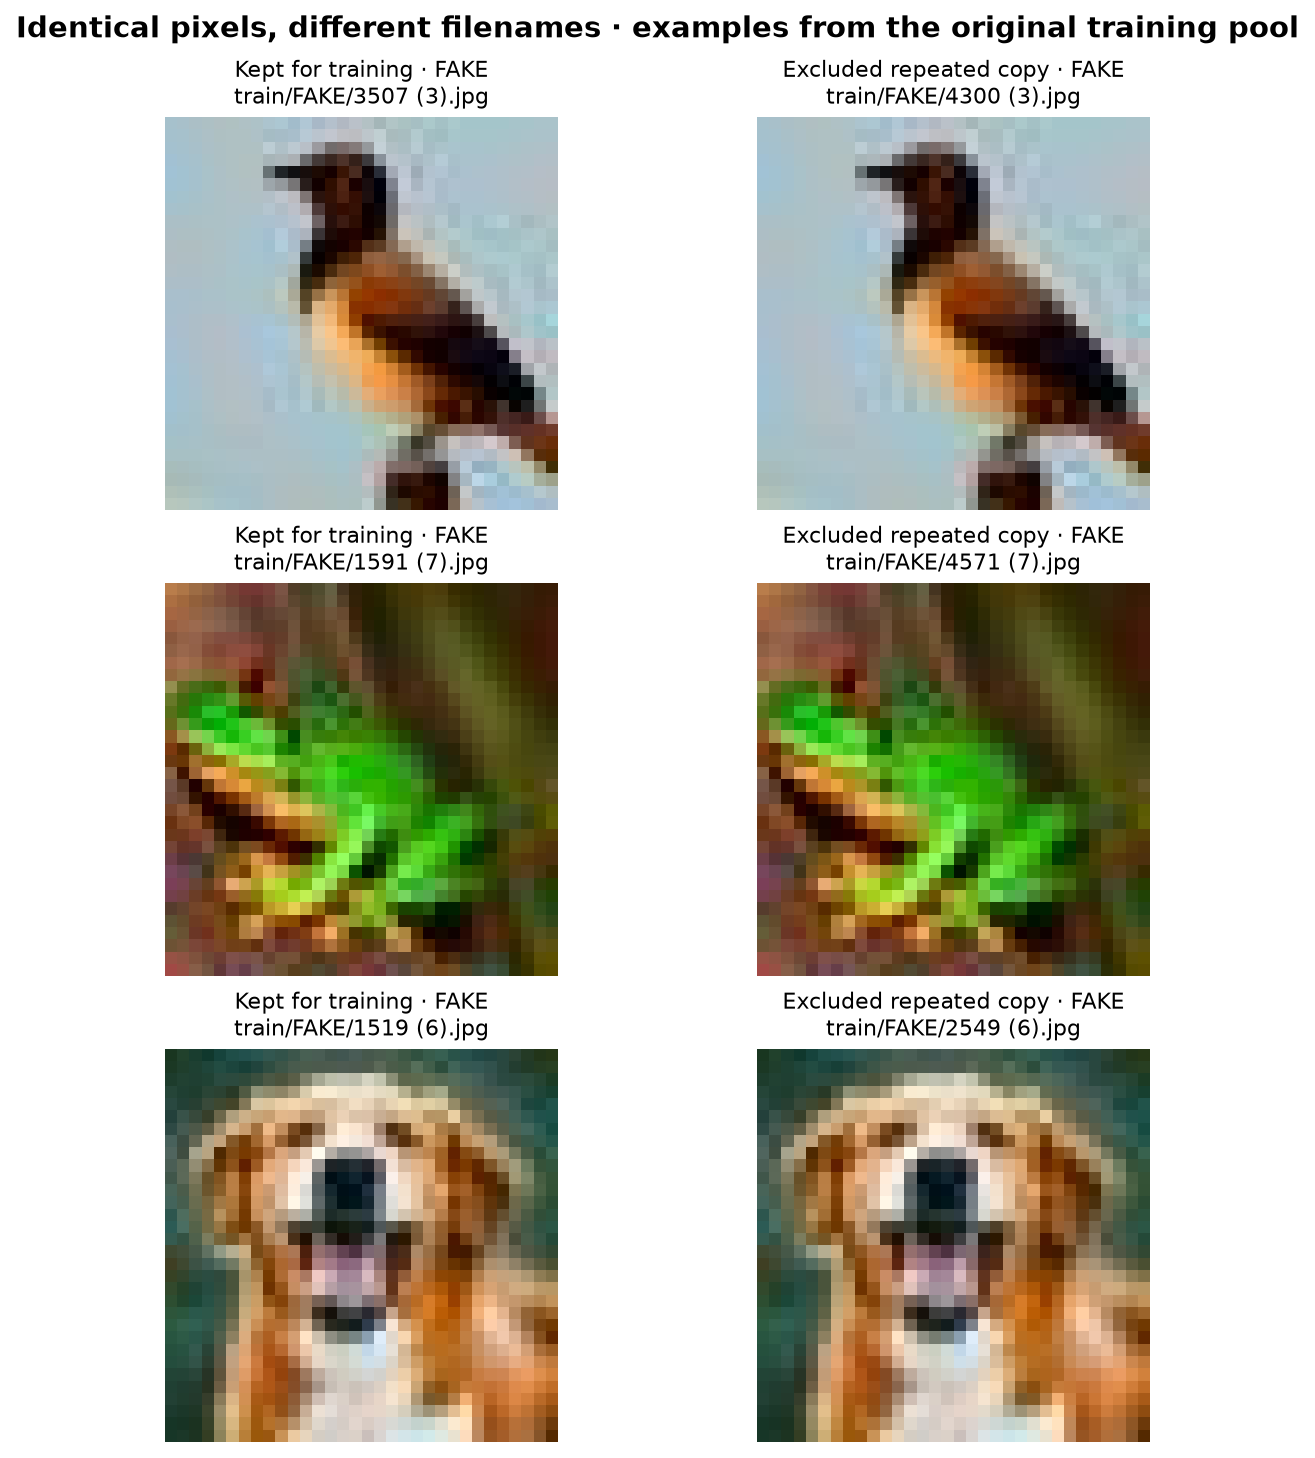

Bundled training-data visualization; no local dataset is required.


In [12]:
# Only display original-development pairs: one kept for TRAIN, one excluded repeat.
# Official test pixels are not opened for this illustration.
if eda_manifest and RAW_DATA.exists():
    duplicate_groups = defaultdict(list)
    for row in eda_manifest:
        if row["source_split"] == "train":
            duplicate_groups[row["pixel_sha256"]].append(row)
    duplicate_pairs = []
    for pixel_hash, group in sorted(duplicate_groups.items()):
        kept = next((r for r in group if r["split"] == "train"), None)
        excluded = next(
            (r for r in group if r["exclusion_reason"] == "repeated_training_image"),
            None,
        )
        if kept and excluded:
            duplicate_pairs.append((pixel_hash, kept, excluded))
    pair_rng = np.random.default_rng(EDA_SEED)
    chosen_pairs = [
        duplicate_pairs[i]
        for i in pair_rng.choice(
            len(duplicate_pairs), size=min(3, len(duplicate_pairs)), replace=False
        )
    ]
    fig, axes = plt.subplots(
        len(chosen_pairs),
        2,
        figsize=(7.4, 3.0 * len(chosen_pairs)),
        squeeze=False,
        layout="constrained",
    )
    for row_index, (pixel_hash, kept, excluded) in enumerate(chosen_pairs):
        pair_pixels = []
        for col, (record, role) in enumerate(
            [(kept, "Kept for training"), (excluded, "Excluded repeated copy")]
        ):
            assert record["path"].startswith("train/")
            with PILImage.open(RAW_DATA / record["path"]) as source_image:
                pixels = np.asarray(source_image.convert("RGB"))
            pair_pixels.append(pixels)
            axes[row_index, col].imshow(pixels, interpolation="nearest")
            axes[row_index, col].set_title(
                f"{role} · {record['class_name']}\n{record['path']}", fontsize=10
            )
            axes[row_index, col].axis("off")
        assert np.array_equal(*pair_pixels)
    fig.suptitle(
        "Identical pixels, different filenames · examples from the original training pool",
        fontsize=13,
        fontweight="bold",
    )
    finish_eda_figure(fig, "02_duplicate_examples")
    del duplicate_groups
else:
    show_saved_eda("02_duplicate_examples")


### 4.2 Balanced random gallery

Before reducing the images to numbers, it helps to get a feel for what the dataset actually looks like. We'll randomly select twelve real and twelve fake images from the cleaned training split and display them in a grid, with real images in the first two rows and fake images in the last two. A fixed random seed means everyone sees the same examples when rerunning the notebook. Look at the backgrounds, edges, textures, and overall composition, and consider which images would be difficult to classify by eye. The images are enlarged without smoothing so we can still see their original 32×32 pixels. This is a small random sample; the object categories are not matched between the two groups.

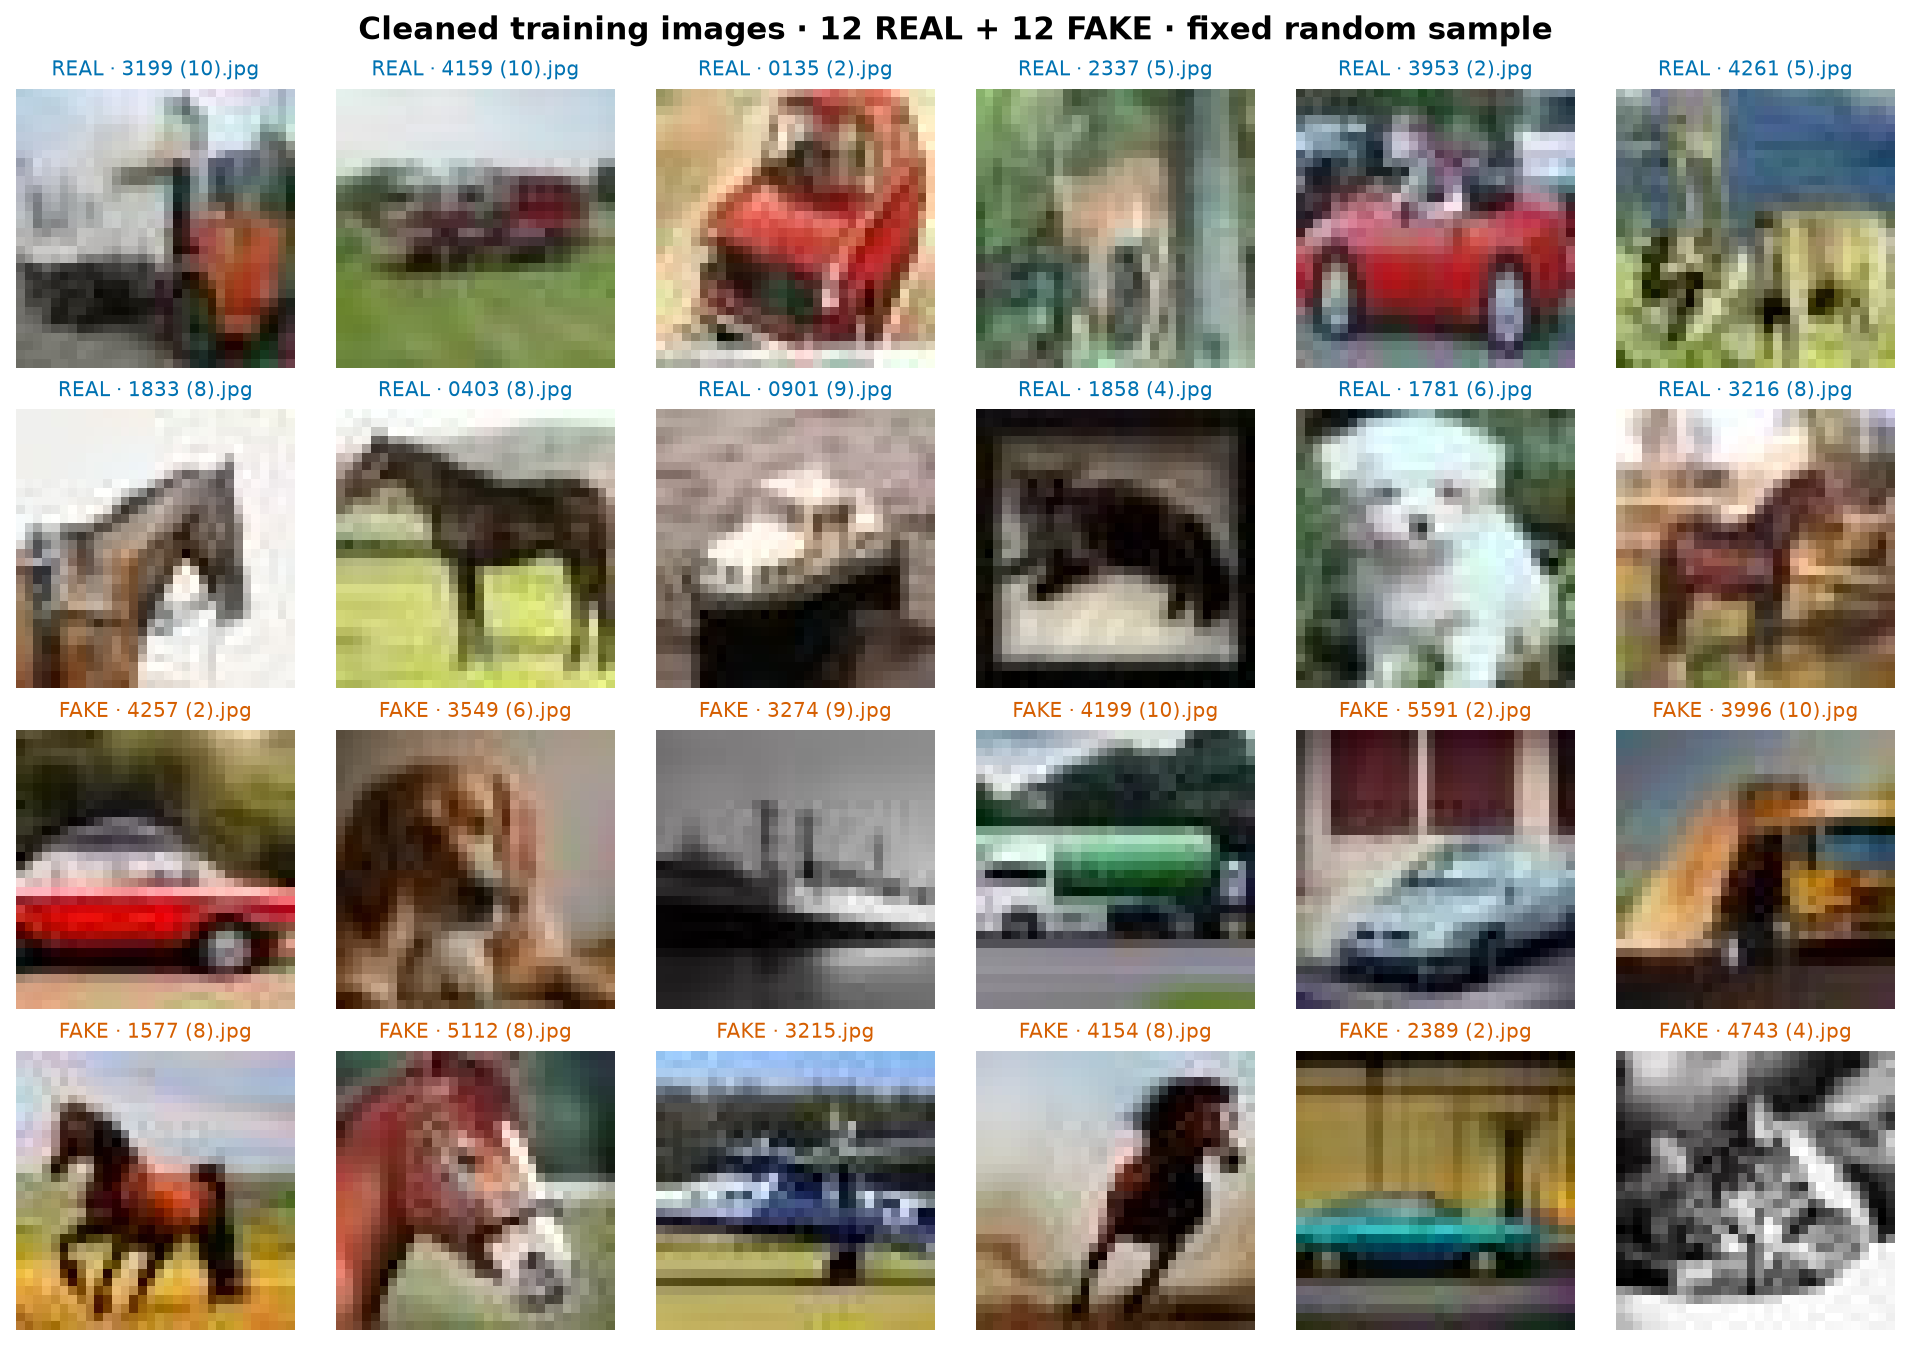

Bundled training-data visualization; no local dataset is required.


In [13]:
if eda_images is not None:
    gallery_rng = np.random.default_rng(EDA_SEED)
    fig, axes = plt.subplots(4, 6, figsize=(12, 8.3), layout="constrained")
    for class_index, (name, label) in enumerate(EDA_CLASS_ORDER):
        chosen = gallery_rng.choice(
            np.flatnonzero(eda_labels == label), size=12, replace=False
        )
        for local_index, image_index in enumerate(chosen):
            ax = axes[class_index * 2 + local_index // 6, local_index % 6]
            ax.imshow(
                eda_images[image_index].transpose(1, 2, 0), interpolation="nearest"
            )
            ax.set_title(
                f"{name} · {Path(eda_rows[image_index]['path']).name}",
                fontsize=9,
                color=EDA_COLORS[name],
            )
            ax.axis("off")
    fig.suptitle(
        "Cleaned training images · 12 REAL + 12 FAKE · fixed random sample",
        fontsize=14,
        fontweight="bold",
    )
    finish_eda_figure(fig, "03_random_gallery")
else:
    show_saved_eda("03_random_gallery")


### 4.3 Image-property distributions

All four properties are calculated on native 32×32 pixels scaled to `[0, 1]`:

- **Brightness:** mean of luma `0.299 R + 0.587 G + 0.114 B`. This is a weighted pixel-value proxy, not calibrated physical luminance.
- **Contrast:** standard deviation of that luma within an image.
- **Saturation:** mean HSV saturation `(max(R,G,B) − min(R,G,B)) / max(R,G,B)`, with zero for black pixels.
- **Sharpness proxy:** variance of the four-neighbour discrete Laplacian, evaluated on the 30×30 interior to avoid padding artifacts. This also responds to noise and compression; it does not measure perceptual sharpness alone.

The sharpness plot uses `log10(variance + 1e-8)` to show its skewed range. Both classes use the same bin edges, and each histogram is normalized separately to density because their training counts differ slightly. No observations are trimmed.

In [14]:
# Measure brightness, colour and texture on training images to understand the data before modeling.
def compute_training_properties(images, labels, batch_size=1024):
    """Four image properties and equal-image-weight, normalized 2-D spectra."""
    properties = np.empty((len(images), 4), dtype=np.float64)
    spectrum_sums = {label: np.zeros((32, 32), dtype=np.float64) for label in (0, 1)}
    spectrum_counts = {label: 0 for label in (0, 1)}
    window = np.outer(np.hanning(32), np.hanning(32)).astype(np.float32)
    weights = np.array([0.299, 0.587, 0.114], dtype=np.float32)
    for start in range(0, len(images), batch_size):
        stop = min(start + batch_size, len(images))
        rgb = images[start:stop].astype(np.float32) / 255
        luma = np.einsum("nchw,c->nhw", rgb, weights)
        channel_max, channel_min = rgb.max(axis=1), rgb.min(axis=1)
        saturation = np.divide(
            channel_max - channel_min,
            channel_max,
            out=np.zeros_like(channel_max),
            where=channel_max > 0,
        )
        laplacian = (
            luma[:, :-2, 1:-1]
            + luma[:, 2:, 1:-1]
            + luma[:, 1:-1, :-2]
            + luma[:, 1:-1, 2:]
            - 4 * luma[:, 1:-1, 1:-1]
        )
        properties[start:stop] = np.column_stack(
            [
                luma.mean(axis=(1, 2)),
                luma.std(axis=(1, 2)),
                saturation.mean(axis=(1, 2)),
                laplacian.var(axis=(1, 2)),
            ]
        )
        # A Hann window limits boundary discontinuities; weighted centering removes DC.
        weighted_mean = (luma * window).sum(axis=(1, 2), keepdims=True) / window.sum()
        transformed = np.fft.fftshift(
            np.fft.fft2((luma - weighted_mean) * window, axes=(-2, -1)), axes=(-2, -1)
        )
        power = np.abs(transformed) ** 2
        power[:, 16, 16] = 0
        total_energy = power.sum(axis=(1, 2), keepdims=True)
        nonconstant = luma.std(axis=(1, 2)) > 1e-7
        valid = nonconstant & (total_energy[:, 0, 0] > 1e-12)
        normalized = np.divide(
            power, total_energy, out=np.zeros_like(power), where=total_energy > 1e-12
        )
        for label in (0, 1):
            mask = (labels[start:stop] == label) & valid
            spectrum_sums[label] += normalized[mask].sum(axis=0, dtype=np.float64)
            spectrum_counts[label] += int(mask.sum())
    spectra = {
        label: spectrum_sums[label] / max(spectrum_counts[label], 1) for label in (0, 1)
    }
    return properties, spectra, spectrum_counts


# Sanity checks have known properties: constant gray, solid red, and a checkerboard.
check_images = np.full((3, 3, 32, 32), 102, dtype=np.uint8)
check_images[1] = 0
check_images[1, 0] = 255
checker = ((np.indices((32, 32)).sum(axis=0) % 2) * 255).astype(np.uint8)
check_images[2] = np.repeat(checker[None, :, :], 3, axis=0)
check_properties, _, check_spectra_counts = compute_training_properties(
    check_images, np.array([0, 0, 1])
)
assert np.allclose(check_properties[0], [0.4, 0, 0, 0], atol=1e-6)
assert np.isclose(check_properties[1, 0], 0.299, atol=1e-6) and np.isclose(
    check_properties[1, 2], 1
)
assert check_properties[2, 3] > check_properties[0, 3]
assert check_spectra_counts == {0: 0, 1: 1}

eda_features, eda_spectra, eda_spectrum_counts = None, None, None
eda_property_stats = {}
if eda_images is not None:
    eda_features, eda_spectra, eda_spectrum_counts = compute_training_properties(
        eda_images, eda_labels
    )
    assert np.isfinite(eda_features).all() and (eda_features >= 0).all()
    assert (eda_features[:, [0, 2]] <= 1 + 1e-6).all()
    assert all(
        np.isclose(spectrum.sum(), 1, atol=1e-5) for spectrum in eda_spectra.values()
    )
    for name, label in EDA_CLASS_ORDER:
        class_features = eda_features[eda_labels == label]
        eda_property_stats[name] = {
            prop: {
                "mean": float(np.mean(class_features[:, col])),
                "median": float(np.median(class_features[:, col])),
                "p10": float(np.quantile(class_features[:, col], 0.1)),
                "p90": float(np.quantile(class_features[:, col], 0.9)),
            }
            for col, prop in enumerate(EDA_PROPERTIES)
        }
    print(
        f"Computed image properties and spectra for all {len(eda_features):,} cleaned training images."
    )
    print("Numerical checks passed; each class-average normalized spectrum sums to 1.")


The next four plots will help us see whether the impressions from the gallery hold across the whole training set. For every image, we'll calculate brightness, contrast, saturation, and a sharpness score, then group the values into bins and overlay the real and fake distributions. Blue represents real images and orange represents fake images. Both groups use the same bins, and each distribution is scaled to have a total area of one so their slightly different image counts do not distort the comparison. The dashed lines mark the medians. Look for shifts in the typical values as well as the amount of overlap; a difference in the medians does not mean that a property can reliably identify every image. Sharpness is shown on a logarithmic scale to make its wide range easier to read.

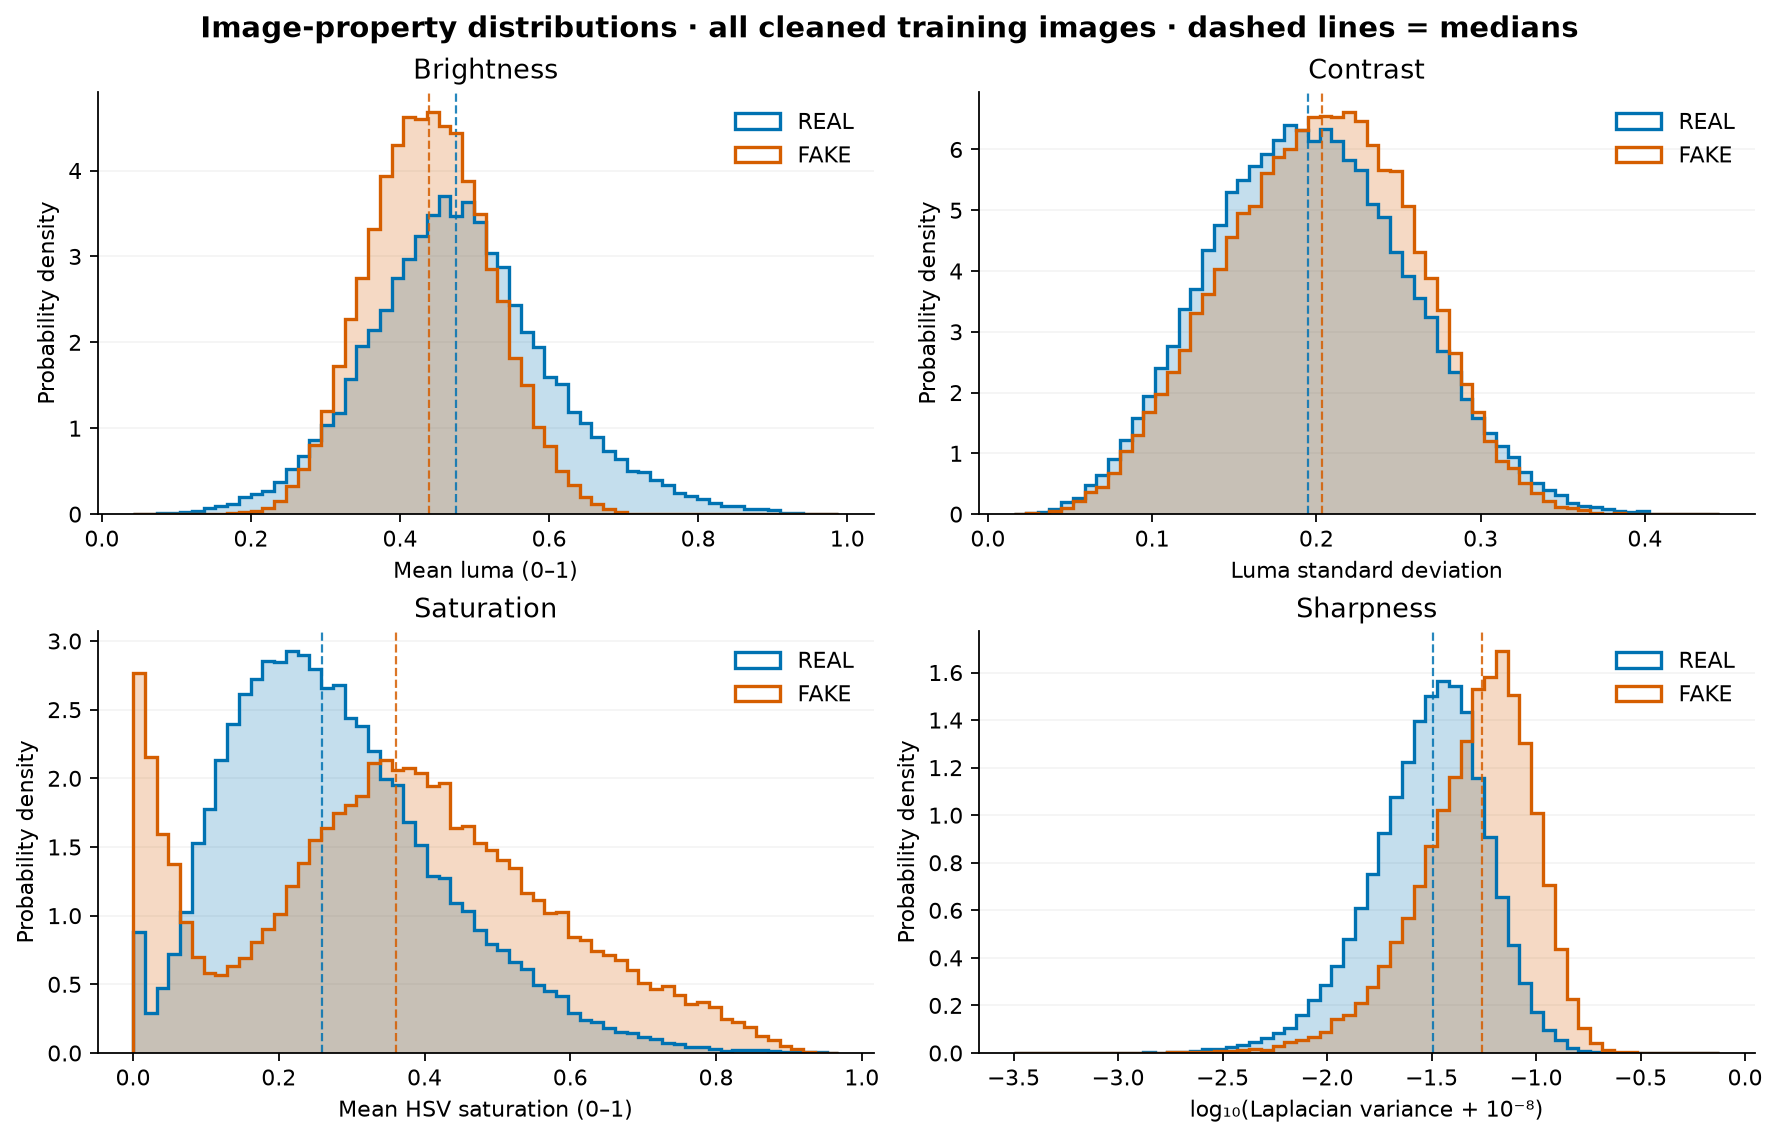

Bundled training-data visualization; no local dataset is required.


In [15]:
if eda_features is not None:
    fig, axes = plt.subplots(2, 2, figsize=(11, 7), layout="constrained")
    for col, (prop, ax) in enumerate(zip(EDA_PROPERTIES, axes.flat)):
        values = (
            np.log10(eda_features[:, col] + 1e-8)
            if prop == "sharpness"
            else eda_features[:, col]
        )
        bins = np.linspace(values.min(), values.max(), 61)
        for name, label in EDA_CLASS_ORDER:
            group = values[eda_labels == label]
            ax.hist(
                group,
                bins=bins,
                density=True,
                histtype="stepfilled",
                alpha=0.23,
                color=EDA_COLORS[name],
            )
            ax.hist(
                group,
                bins=bins,
                density=True,
                histtype="step",
                lw=1.5,
                color=EDA_COLORS[name],
                label=name,
            )
            ax.axvline(
                np.median(group), color=EDA_COLORS[name], ls="--", lw=1, alpha=0.85
            )
        key = "log_sharpness" if prop == "sharpness" else prop
        ax.set(
            title=prop.title(),
            xlabel=EDA_PROPERTY_LABELS[key],
            ylabel="Probability density",
        )
        ax.legend(frameon=False)
        style_eda_axes(ax)
    fig.suptitle(
        "Image-property distributions · all cleaned training images · dashed lines = medians",
        fontsize=13,
        fontweight="bold",
    )
    finish_eda_figure(fig, "04_property_distributions")
    show_table(
        [
            "Property (original units)",
            "Class",
            "Mean",
            "Median",
            "10th–90th percentile",
        ],
        [
            [
                prop,
                name,
                f"{eda_property_stats[name][prop]['mean']:.4g}",
                f"{eda_property_stats[name][prop]['median']:.4g}",
                f"{eda_property_stats[name][prop]['p10']:.4g}–{eda_property_stats[name][prop]['p90']:.4g}",
            ]
            for prop in EDA_PROPERTIES
            for name, _ in EDA_CLASS_ORDER
        ],
    )
else:
    show_saved_eda("04_property_distributions")


### 4.4 Connect the sharpness proxy to actual images

A sharpness score is easier to understand when we can see the images behind it. We'll rank the training images by Laplacian variance and display the four lowest-scoring and four highest-scoring examples separately for real and fake images. The low-score rows will let us inspect images with little variation in local edges, while the high-score rows will show what produces a strong response. As we compare them, we'll look for blur, detailed textures, repeated patterns, or noise that might explain the scores. These examples were deliberately chosen from the extremes, so they should not be treated as typical real or fake images. A high value also does not automatically mean better image quality.

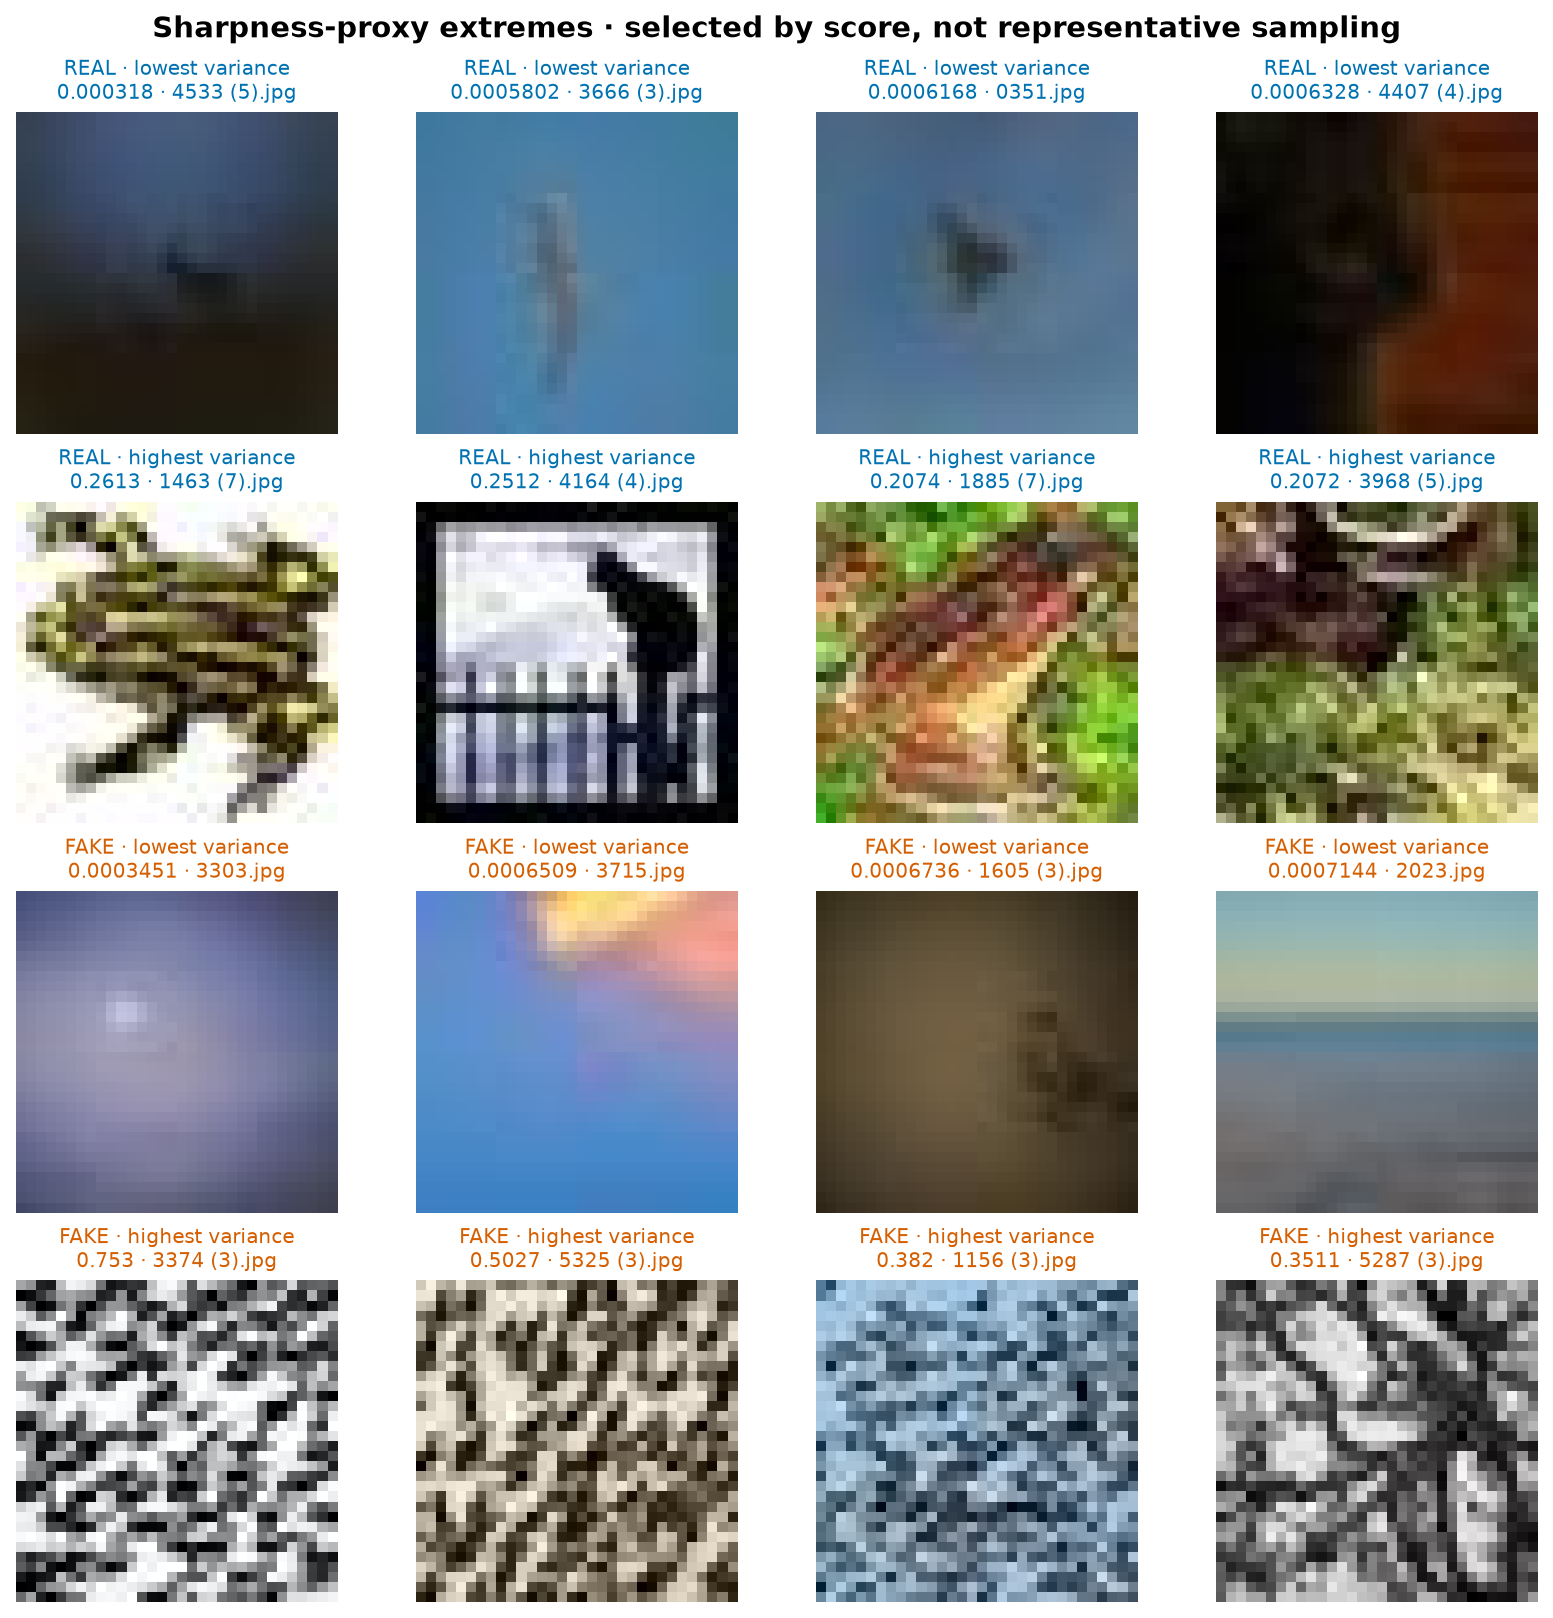

Bundled training-data visualization; no local dataset is required.


In [16]:
if eda_features is not None:
    fig, axes = plt.subplots(4, 4, figsize=(10, 10), layout="constrained")
    for class_index, (name, label) in enumerate(EDA_CLASS_ORDER):
        members = np.flatnonzero(eda_labels == label)
        ordered = members[np.argsort(eda_features[members, 3], kind="stable")]
        for which, selected in enumerate([ordered[:4], ordered[-4:][::-1]]):
            for col, index in enumerate(selected):
                ax = axes[2 * class_index + which, col]
                ax.imshow(eda_images[index].transpose(1, 2, 0), interpolation="nearest")
                ax.set_title(
                    f"{name} · {'lowest' if which == 0 else 'highest'} variance\n{eda_features[index, 3]:.4g} · {Path(eda_rows[index]['path']).name}",
                    fontsize=9,
                    color=EDA_COLORS[name],
                )
                ax.axis("off")
    fig.suptitle(
        "Sharpness-proxy extremes · selected by score, not representative sampling",
        fontsize=13,
        fontweight="bold",
    )
    finish_eda_figure(fig, "05_sharpness_extremes")
else:
    show_saved_eda("05_sharpness_extremes")


### 4.5 Link image properties to thumbnails

The histograms show one property at a time, but two properties may tell a different story when we look at them together. Here we'll plot the sharpness score on the horizontal axis, using a logarithmic scale, and contrast on the vertical axis. Each point represents one training image, with blue for real images and orange for fake images. We'll use a fixed random sample of 800 images from each group to keep the plot readable and give both classes equal representation. Look for any relationship between contrast and sharpness, for points that sit far from the others, and for regions where the two colours overlap. The colours show the dataset labels; no model predictions are involved in this plot.

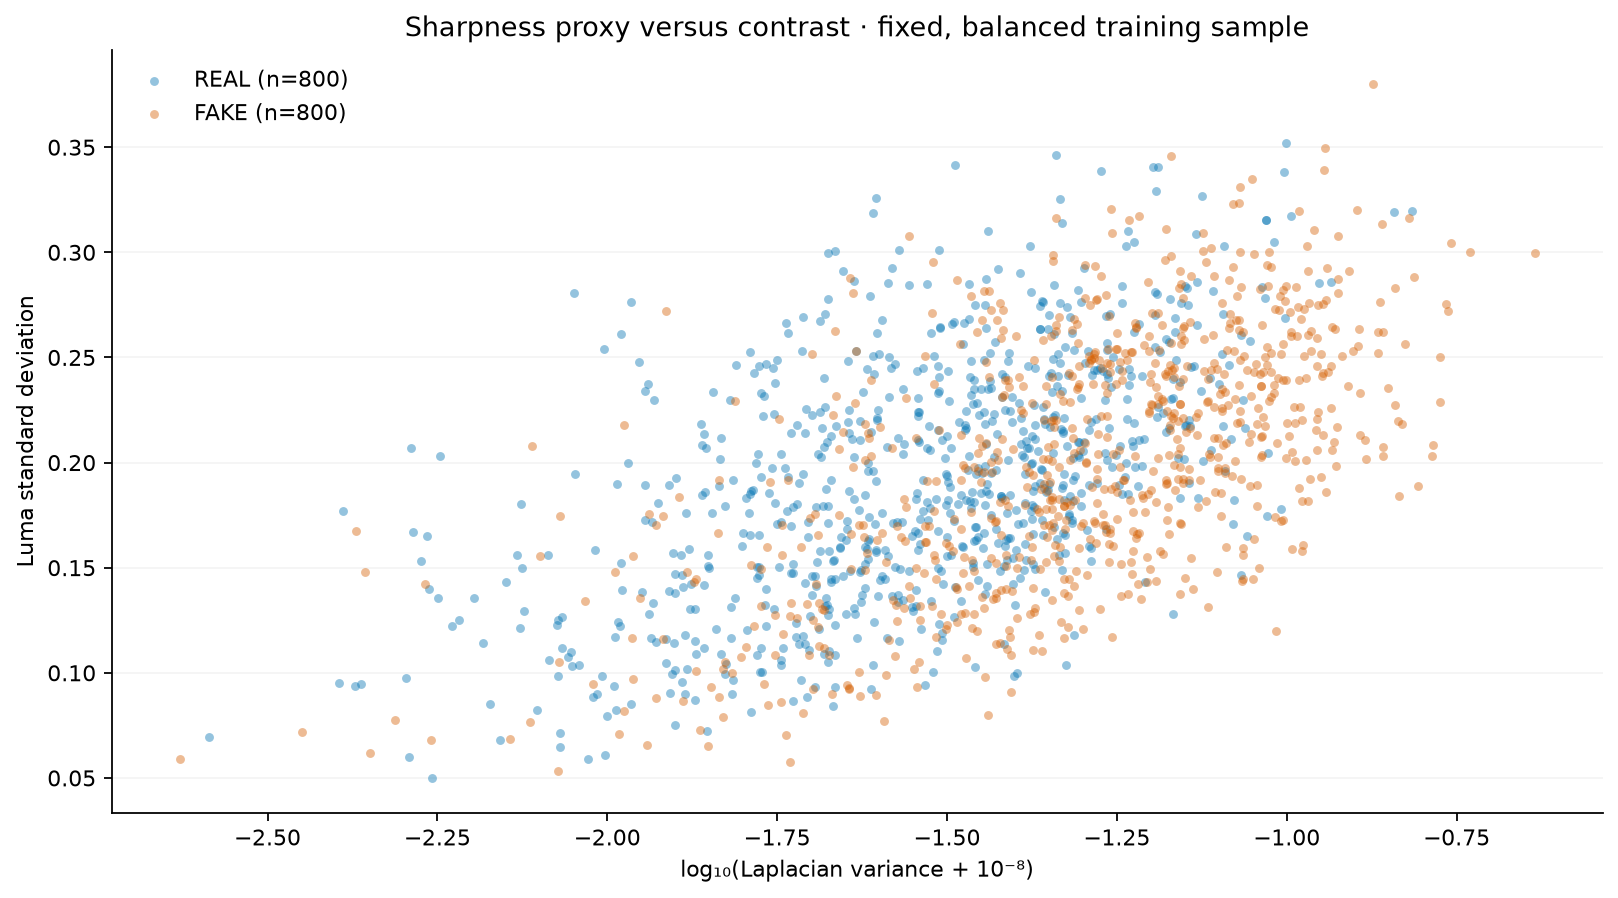

Bundled training-data visualization; no local dataset is required.


In [17]:
eda_scatter_indices = None
if eda_features is not None:
    scatter_rng = np.random.default_rng(EDA_SEED)
    eda_scatter_indices = np.concatenate(
        [
            scatter_rng.choice(
                np.flatnonzero(eda_labels == label),
                size=min(800, int((eda_labels == label).sum())),
                replace=False,
            )
            for _, label in EDA_CLASS_ORDER
        ]
    )
    eda_plot_values = {
        prop: eda_features[:, col] for col, prop in enumerate(EDA_PROPERTIES)
    }
    eda_plot_values["log_sharpness"] = np.log10(eda_features[:, 3] + 1e-8)
    fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")
    for name, label in EDA_CLASS_ORDER:
        ids = eda_scatter_indices[eda_labels[eda_scatter_indices] == label]
        ax.scatter(
            eda_plot_values["log_sharpness"][ids],
            eda_plot_values["contrast"][ids],
            c=EDA_COLORS[name],
            s=16,
            alpha=0.42,
            linewidths=0,
            label=f"{name} (n={len(ids)})",
        )
    ax.set(
        xlabel=EDA_PROPERTY_LABELS["log_sharpness"],
        ylabel=EDA_PROPERTY_LABELS["contrast"],
        title="Sharpness proxy versus contrast · fixed, balanced training sample",
    )
    style_eda_axes(ax)
    ax.legend(frameon=False)
    finish_eda_figure(fig, "06_scatter_overview")
else:
    show_saved_eda("06_scatter_overview")


We can now connect those points back to the actual pictures. The interactive version uses the same sampled images, but lets us change the properties on either axis, zoom into a region, and hide or show a class through the legend. Clicking a point will display its image, filename, and measurements below the chart. For example, we can select a point with unusually high sharpness and inspect whether it contains fine texture or a noisy pattern. This gives us a way to investigate patterns rather than guess what an isolated point represents. Run the cell with a live notebook kernel and the prepared training data to enable the interactions; the static plot above remains available on GitHub.

In [18]:
if eda_scatter_indices is not None:
    try:
        import plotly.graph_objects as go
        import ipywidgets as widgets
        import anywidget  # FigureWidget's Jupyter widget backend
    except ImportError:
        print(
            "Install the pinned requirements and restart the kernel for the clickable explorer. The static scatterplot remains available above."
        )
    else:
        explorer_ids = {
            name: eda_scatter_indices[eda_labels[eda_scatter_indices] == label]
            for name, label in EDA_CLASS_ORDER
        }
        axis_options = [
            (EDA_PROPERTY_LABELS[key], key)
            for key in ("brightness", "contrast", "saturation", "log_sharpness")
        ]
        explorer_x = widgets.Dropdown(
            options=axis_options,
            value="log_sharpness",
            description="X axis:",
            layout=widgets.Layout(width="47%"),
        )
        explorer_y = widgets.Dropdown(
            options=axis_options,
            value="contrast",
            description="Y axis:",
            layout=widgets.Layout(width="47%"),
        )
        explorer_figure = go.FigureWidget()
        for name, _ in EDA_CLASS_ORDER:
            ids = explorer_ids[name]
            explorer_figure.add_scatter(
                x=eda_plot_values[explorer_x.value][ids],
                y=eda_plot_values[explorer_y.value][ids],
                name=name,
                mode="markers",
                customdata=[eda_rows[int(i)]["path"] for i in ids],
                marker=dict(size=6, color=EDA_COLORS[name], opacity=0.55),
                hovertemplate="%{customdata}<br>x=%{x:.4f}<br>y=%{y:.4f}<extra>%{fullData.name}</extra>",
            )
        explorer_figure.add_scatter(
            x=[],
            y=[],
            name="Selected",
            mode="markers",
            hoverinfo="skip",
            showlegend=False,
            marker=dict(
                size=16, color="#242424", symbol="circle-open", line=dict(width=2)
            ),
        )
        explorer_figure.update_layout(
            template="plotly_white",
            height=440,
            margin=dict(l=65, r=20, t=55, b=60),
            title="Click a training-image point to inspect it below",
            clickmode="event",
            xaxis_title=EDA_PROPERTY_LABELS[explorer_x.value],
            yaxis_title=EDA_PROPERTY_LABELS[explorer_y.value],
            legend=dict(orientation="h", y=1.05, x=0.75),
        )
        explorer_image = widgets.Image(format="png", width=160, height=160)
        explorer_details = widgets.HTML(layout=widgets.Layout(margin="0 0 0 18px"))
        explorer_selection = {"index": int(explorer_ids["REAL"][0])}

        def select_training_image(index):
            index = int(index)
            assert eda_rows[index]["split"] == "train"
            explorer_selection["index"] = index
            buffer = BytesIO()
            PILImage.fromarray(eda_images[index].transpose(1, 2, 0)).resize(
                (160, 160), resample=PILImage.Resampling.NEAREST
            ).save(buffer, format="PNG")
            explorer_image.value = buffer.getvalue()
            name = "REAL" if eda_labels[index] == 1 else "FAKE"
            stats_html = "<br>".join(
                f"{html.escape(EDA_PROPERTY_LABELS[prop])}: <b>{eda_features[index, col]:.4f}</b>"
                for col, prop in enumerate(EDA_PROPERTIES)
            )
            explorer_details.value = (
                f"<b style='color:{EDA_COLORS[name]}'>{name}</b> · training image<br>"
                f"<code>{html.escape(eda_rows[index]['path'])}</code><br><br>{stats_html}"
                "<br><small>32×32 source, enlarged with nearest-neighbor sampling.</small>"
            )
            with explorer_figure.batch_update():
                explorer_figure.data[2].x = [eda_plot_values[explorer_x.value][index]]
                explorer_figure.data[2].y = [eda_plot_values[explorer_y.value][index]]

        def on_training_image_click(trace, points, selector):
            if points.point_inds:
                select_training_image(explorer_ids[trace.name][points.point_inds[0]])

        def update_explorer_axes(change):
            with explorer_figure.batch_update():
                for trace in explorer_figure.data[:2]:
                    ids = explorer_ids[trace.name]
                    trace.x = eda_plot_values[explorer_x.value][ids]
                    trace.y = eda_plot_values[explorer_y.value][ids]
                explorer_figure.layout.xaxis.title = EDA_PROPERTY_LABELS[
                    explorer_x.value
                ]
                explorer_figure.layout.yaxis.title = EDA_PROPERTY_LABELS[
                    explorer_y.value
                ]
                index = explorer_selection["index"]
                explorer_figure.data[2].x = [eda_plot_values[explorer_x.value][index]]
                explorer_figure.data[2].y = [eda_plot_values[explorer_y.value][index]]

        for trace in explorer_figure.data[:2]:
            trace.on_click(on_training_image_click)
        explorer_x.observe(update_explorer_axes, names="value")
        explorer_y.observe(update_explorer_axes, names="value")
        select_training_image(explorer_selection["index"])
        display(
            widgets.VBox(
                [
                    widgets.HBox([explorer_x, explorer_y]),
                    explorer_figure,
                    widgets.HBox([explorer_image, explorer_details]),
                ]
            )
        )
        print(
            "Requires a running notebook kernel for thumbnail clicks and axis changes. The static plot above works in GitHub previews."
        )
else:
    print(
        "Interactive thumbnails need the prepared training data. Saved static plots above can be reviewed without it."
    )


Interactive thumbnails need the prepared training data. Saved static plots above can be reviewed without it.


### 4.6 Spatial-frequency patterns

Next we'll compare how broad shapes and fine detail are distributed across the two groups. We'll convert each training image to a single brightness channel and use a Fourier transform to describe its spatial-frequency content. Slowly changing areas contribute to lower frequencies, while finer textures and rapid changes between neighbouring pixels contribute to higher frequencies. Averaging the results separately for real and fake images will give us the two heatmaps below. Their centres represent low frequencies, and positions farther from the centre represent finer detail. Both heatmaps use the same colour scale, so their intensities can be compared directly.

To make the comparison fair, we subtract each image's Hann-weighted mean, apply a Hann window to soften boundary effects, and remove the zero-frequency bin, which represents the average brightness. We then scale each usable image's remaining power to sum to one before averaging, so high-contrast images do not dominate the result. Constant or effectively zero-energy images are excluded and counted below. The colours use a logarithmic scale so weaker frequency components remain visible.

The line plot on the right will make the comparison easier to follow by averaging bins at similar distances from the centre. Moving right corresponds to finer detail; a higher curve means more normalized power per frequency bin at that distance. This is not the total energy in each ring. Frequencies are measured in cycles per pixel, and diagonal distances can exceed 0.5. We'll look for ranges where the curves differ, while keeping in mind that image content, compression, and other processing can also produce these differences. The plots alone cannot tell us whether the CNN uses them.

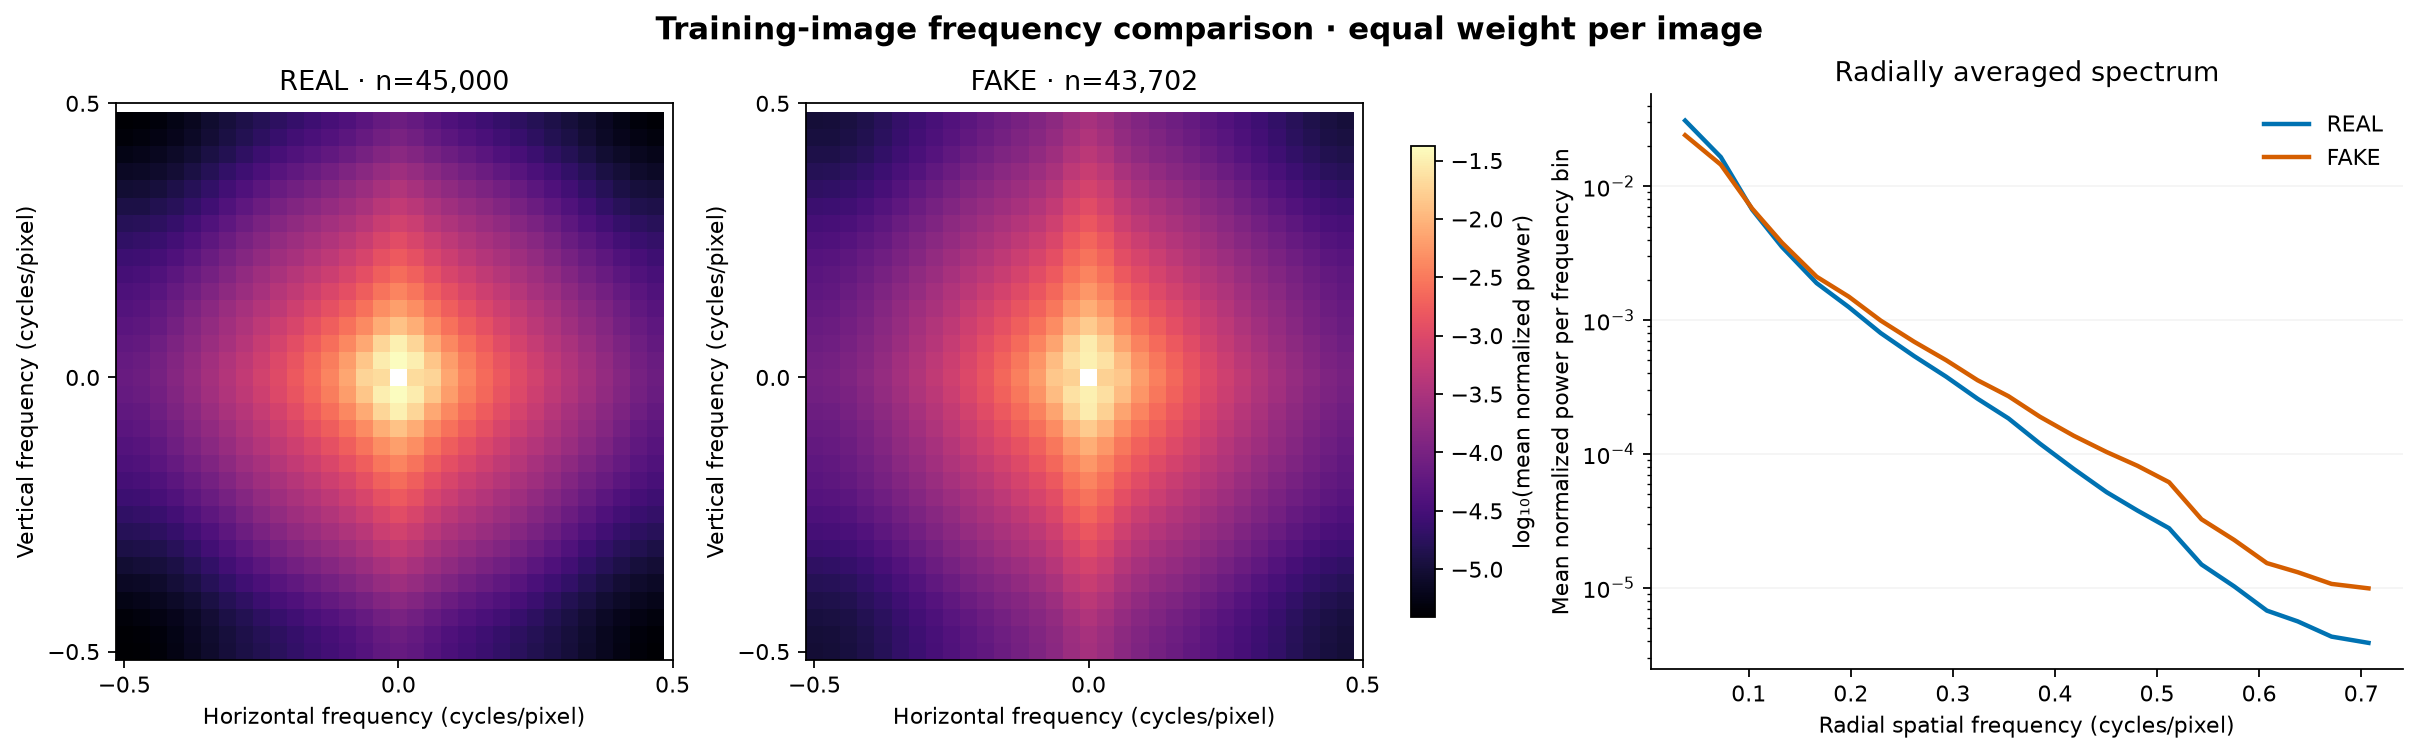

Bundled training-data visualization; no local dataset is required.


In [19]:
# Average spatial-frequency profiles over training images to compare fine detail between the classes.
if eda_spectra is not None:
    frequencies = np.fft.fftshift(np.fft.fftfreq(32))
    freq_x, freq_y = np.meshgrid(frequencies, frequencies)
    eda_frequency_radius = np.hypot(freq_x, freq_y)
    rings = np.floor(eda_frequency_radius * 32).astype(int)
    ring_counts = np.bincount(rings.ravel())
    ring_radius = (
        np.bincount(rings.ravel(), weights=eda_frequency_radius.ravel()) / ring_counts
    )
    nonzero_rings = (ring_counts > 0) & (np.arange(len(ring_counts)) > 0)
    log_spectra = {
        label: np.ma.masked_where(eda_frequency_radius == 0, np.log10(spectrum + 1e-12))
        for label, spectrum in eda_spectra.items()
    }
    color_min = min(float(s.min()) for s in log_spectra.values())
    color_max = max(float(s.max()) for s in log_spectra.values())
    fig, axes = plt.subplots(
        1,
        3,
        figsize=(15, 4.6),
        layout="constrained",
        gridspec_kw={"width_ratios": [1, 1, 1.35]},
    )
    for ax, (name, label) in zip(axes[:2], EDA_CLASS_ORDER):
        heat = ax.imshow(
            log_spectra[label],
            origin="lower",
            cmap="magma",
            vmin=color_min,
            vmax=color_max,
            extent=(-0.5 - 1 / 64, 0.5 - 1 / 64, -0.5 - 1 / 64, 0.5 - 1 / 64),
            interpolation="nearest",
        )
        ax.set(
            title=f"{name} · n={eda_spectrum_counts[label]:,}",
            xlabel="Horizontal frequency (cycles/pixel)",
            ylabel="Vertical frequency (cycles/pixel)",
            xticks=[-0.5, 0, 0.5],
            yticks=[-0.5, 0, 0.5],
        )
    colorbar = fig.colorbar(heat, ax=list(axes[:2]), shrink=0.82, pad=0.025)
    colorbar.set_label("log₁₀(mean normalized power)")
    for name, label in EDA_CLASS_ORDER:
        profile = (
            np.bincount(rings.ravel(), weights=eda_spectra[label].ravel()) / ring_counts
        )
        axes[2].plot(
            ring_radius[nonzero_rings],
            profile[nonzero_rings],
            color=EDA_COLORS[name],
            label=name,
            linewidth=2,
        )
    axes[2].set(
        xlabel="Radial spatial frequency (cycles/pixel)",
        ylabel="Mean normalized power per frequency bin",
        title="Radially averaged spectrum",
        yscale="log",
    )
    axes[2].legend(frameon=False)
    style_eda_axes(axes[2])
    fig.suptitle(
        "Training-image frequency comparison · equal weight per image",
        fontweight="bold",
        fontsize=14,
    )
    finish_eda_figure(fig, "07_frequency_comparison")
    for name, label in EDA_CLASS_ORDER:
        excluded = int((eda_labels == label).sum()) - eda_spectrum_counts[label]
        print(
            f"{name}: {eda_spectrum_counts[label]:,} usable spectra; {excluded} constant/zero-energy images excluded."
        )
else:
    show_saved_eda("07_frequency_comparison")


### 4.7 Record the observations

The completed figures and numerical summary are bundled inside this notebook. Set `SAVE_FIGURES = True` to also save recalculated figures locally in `results/eda_baseline_seed1/`. Galleries and the scatterplot use seed 2026; property distributions and frequency averages use the entire cleaned training split. Thumbnail enlargement is for display only and is not training augmentation.

Read the property medians together with the distributions and example images. Class distributions can overlap substantially even when their medians differ. These plots generate hypotheses for later validation-set experiments, such as blur or color perturbations; they do not establish which cues the CNN learned. Keep the completed baseline and test results fixed when designing those follow-up experiments.

In [20]:
eda_summary = None
if eda_features is not None:
    eda_summary = {
        "source_split": "train",
        "split_seed": SPLIT_SEED,
        "sampling_seed": EDA_SEED,
        "manifest_sha256": file_sha256(DATA_DIR / "manifest.csv"),
        "image_shape_chw": list(eda_images.shape[1:]),
        "image_count": len(eda_images),
        "class_counts": {
            name: int((eda_labels == label).sum()) for name, label in EDA_CLASS_ORDER
        },
        "property_definitions": {
            "brightness": "Mean of 0.299R + 0.587G + 0.114B, RGB scaled to [0,1]",
            "contrast": "Population standard deviation of luma",
            "saturation": "Mean HSV saturation: (max(RGB)-min(RGB))/max(RGB), zero for black pixels",
            "sharpness": "Population variance of the four-neighbor luma Laplacian over the 30x30 interior",
        },
        "property_statistics": eda_property_stats,
        "frequency_method": "Hann-weighted centering, 2-D Hann window, FFT power, DC removed, per-image unit-sum normalization, class mean",
        "spectrum_counts": {
            name: eda_spectrum_counts[label] for name, label in EDA_CLASS_ORDER
        },
        "excluded_spectrum_counts": {
            name: int((eda_labels == label).sum()) - eda_spectrum_counts[label]
            for name, label in EDA_CLASS_ORDER
        },
        "mean_energy_fraction_radius_ge_0_25": {
            name: float(eda_spectra[label][eda_frequency_radius >= 0.25].sum())
            for name, label in EDA_CLASS_ORDER
        },
        "gallery_images_per_class": 12,
        "scatter_images_per_class": 800,
        "figures": [p.name for p in sorted(EDA_DIR.glob("*.png"))],
        "scope": "Training pixels only; split audit also reads metadata for all splits. Added after the baseline run; no model or test-result changes.",
        "limitations": [
            "Descriptive class associations do not establish model reliance or causation.",
            "Sharpness is a resolution-dependent proxy, not a direct measure of image quality.",
            "Near-duplicates and semantic-category balance were not audited.",
        ],
    }
    if SAVE_FIGURES:
        write_json(EDA_DIR / "summary.json", eda_summary)
        print("Saved seven figures and summary:", EDA_DIR.relative_to(ROOT))
    else:
        print(
            "Figures and observations are displayed inline; SAVE_FIGURES enables optional local copies."
        )
else:
    eda_summary = (
        read_json(EDA_DIR / "summary.json")
        if (EDA_DIR / "summary.json").exists()
        else None
    )
    if eda_summary is None and SPLIT_SEED == 1:
        eda_summary = json.loads(
            embedded_bytes("results/eda_baseline_seed1/summary.json")
        )

if eda_summary:
    property_stats = eda_summary["property_statistics"]
    real_median = property_stats["REAL"]["sharpness"]["median"]
    fake_median = property_stats["FAKE"]["sharpness"]["median"]
    display(
        Markdown(
            f"**Observed in {eda_summary['image_count']:,} training images:** median Laplacian variance is "
            f"**{real_median:.4f} for REAL** and **{fake_median:.4f} for FAKE**. "
            "Use the distributions and extreme-image gallery above to interpret that difference; "
            "this is an image statistic, not a model attribution."
        )
    )


**Observed in 88,702 training images:** median Laplacian variance is **0.0321 for REAL** and **0.0553 for FAKE**. Use the distributions and extreme-image gallery above to interpret that difference; this is an image statistic, not a model attribution.

## 5. From these observations to Phase I tests

The clearest difference is fine detail. Fake training images have a higher median Laplacian variance (**0.0553** vs **0.0321** for REAL), and **16.1 %** of their normalized spectral power lies in the fine-detail frequencies (radius ≥ 0.25), against **10.9 %** for REAL. Fakes are also more saturated (median **0.36** vs **0.26**) and slightly darker (median brightness 0.44 vs 0.48). Every distribution overlaps heavily, so these are tendencies, not rules.

That gives four testable hypotheses for the trained models:

1. **Removing fine detail should move fakes toward REAL.** Blur and downsize-and-resize do this; `02_cnn_behaviour.ipynb` and `03_resnet18_behaviour.ipynb` test them on 10,000 validation images.
2. **Adding fine detail should move real photos toward FAKE.** Sharpening never appears in training. `04_what_fools_the_detectors.ipynb` adds it as a new edit and also tries to undo blur with it.
3. **Colour could be a second cue.** `04_what_fools_the_detectors.ipynb` desaturates images, alone and after blur, and compares the ten object classes.
4. **If sharpness were the whole story, it would separate the classes on its own.** On the validation images it reaches a ROC-AUC of only 0.73, while *within* every sharpness decile the CNN keeps a ROC-AUC of 0.98–0.99 and ResNet18 above 0.99. `04_what_fools_the_detectors.ipynb` follows this up by object class, colour and image group.

These statistics describe the training data only. They show what a model *could* use, not what it *does* use; the behaviour notebooks measure that.